# SentimentScope: Sentiment Analysis using Transformers

This notebook implements the **SentimentScope** project using the IMDB movie-review dataset.

It follows the supplied starter notebook/rubric:
- Load and explore the 25,000-review IMDB train/test sets.
- Split the training set into 22,500 train and 2,500 validation examples.
- Tokenize with `bert-base-uncased` and `MAX_LENGTH = 128`.
- Implement the required custom PyTorch `IMDBDataset`.
- Customize the supplied GPT-style transformer architecture with a binary classification head.
- Train with CrossEntropyLoss + AdamW.
- Calculate validation and test accuracy.
- Report the final test accuracy and key takeaways.

> **Dataset:** Place `aclImdb_v1.tar.gz` in this project folder, then run the extraction cell. The dataset is intentionally not included in the ZIP because it is large.

## 1. Load, Explore, and Prepare the Dataset

Expected extracted structure:

```text
aclImdb/
├── train/
│   ├── pos/
│   ├── neg/
│   └── unsup/
└── test/
    ├── pos/
    └── neg/
```

Positive reviews use label `1`; negative reviews use label `0`.

In [2]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
import torch.optim as optim

# Extract the dataset if the tar.gz file is present.
# Uncomment if needed:
# !tar -xzf aclImdb_v1.tar.gz

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.0+cpu
CUDA available: False


In [3]:
# Define paths to dataset
train_pos_path = "aclImdb/train/pos"
train_neg_path = "aclImdb/train/neg"
test_pos_path = "aclImdb/test/pos"
test_neg_path = "aclImdb/test/neg"

for path in [train_pos_path, train_neg_path, test_pos_path, test_neg_path]:
    print(path, "->", os.path.exists(path))

aclImdb/train/pos -> False
aclImdb/train/neg -> False
aclImdb/test/pos -> False
aclImdb/test/neg -> False


In [11]:
def load_dataset(folder):
    """Read all .txt review files in a folder and return their contents."""
    reviews = []
    for filename in sorted(os.listdir(folder)):
        if filename.endswith(".txt"):
            file_path = os.path.join(folder, filename)
            with open(file_path, "r", encoding="utf-8") as f:
                reviews.append(f.read())
    return reviews

# Load training and testing data
train_pos = load_dataset(train_pos_path)
train_neg = load_dataset(train_neg_path)
test_pos = load_dataset(test_pos_path)
test_neg = load_dataset(test_neg_path)

print(len(train_pos), len(train_neg), len(test_pos), len(test_neg))

12500 12500 12500 12500


In [12]:
# Create DataFrames
train_df = pd.DataFrame({
    "review": train_pos + train_neg,
    "label": [1] * len(train_pos) + [0] * len(train_neg)
})

test_df = pd.DataFrame({
    "review": test_pos + test_neg,
    "label": [1] * len(test_pos) + [0] * len(test_neg)
})

print(train_df.head())
print(test_df.head())

# Required rubric checks
assert train_df.shape[0] == 25000, "Training dataset does not have 25000 rows."
assert test_df.shape[0] == 25000, "Testing dataset does not have 25000 rows."
assert train_df.shape[1] == 2, "Training dataset does not have exactly 2 columns."
assert test_df.shape[1] == 2, "Testing dataset does not have exactly 2 columns."

print("Dataset dimension assertions passed.")

                                              review  label
0  Bromwell High is a cartoon comedy. It ran at t...      1
1  Homelessness (or Houselessness as George Carli...      1
2  Brilliant over-acting by Lesley Ann Warren. Be...      1
3  This is easily the most underrated film inn th...      1
4  This is not the typical Mel Brooks film. It wa...      1
                                              review  label
0  I went and saw this movie last night after bei...      1
1  Actor turned director Bill Paxton follows up h...      1
2  As a recreational golfer with some knowledge o...      1
3  I saw this film in a sneak preview, and it is ...      1
4  Bill Paxton has taken the true story of the 19...      1
Dataset dimension assertions passed.


In [13]:
# Dataset exploration
print("Training Dataset Info:")
train_df.info()

print("\nTraining descriptive statistics:")
print(train_df.describe(include="all"))

print("\nTest descriptive statistics:")
print(test_df.describe(include="all"))

print("\nTraining label distribution:")
print(train_df["label"].value_counts())

print("\nTest label distribution:")
print(test_df["label"].value_counts())

train_df["review_length"] = train_df["review"].apply(lambda x: len(x.split()))
test_df["review_length"] = test_df["review"].apply(lambda x: len(x.split()))

print("\nReview-length statistics:")
print(train_df["review_length"].describe())

Training Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   review  25000 non-null  str  
 1   label   25000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 390.8 KB

Training descriptive statistics:
                                                   review        label
count                                               25000  25000.00000
unique                                              24904          NaN
top     You do realize that you've been watching the E...          NaN
freq                                                    3          NaN
mean                                                  NaN      0.50000
std                                                   NaN      0.50001
min                                                   NaN      0.00000
25%                                                   NaN      0.00000
50%                

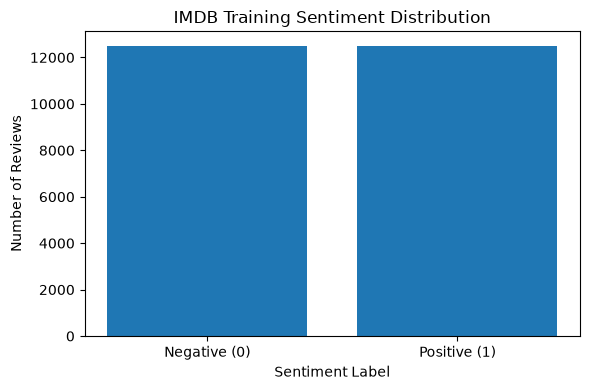

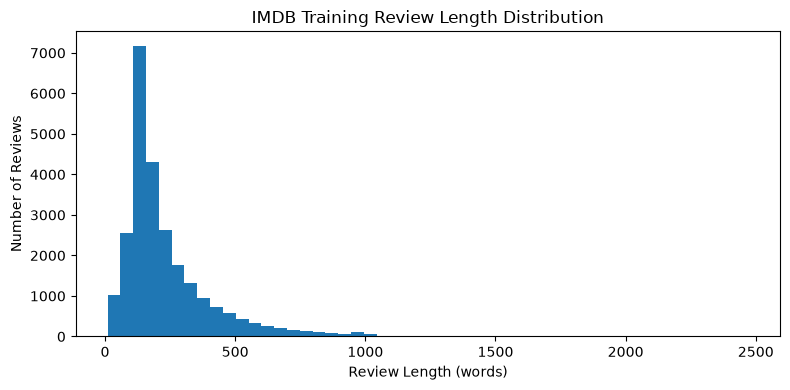

Sample positive review:
 Bromwell High is a cartoon comedy. It ran at the same time as some other programs about school life, such as "Teachers". My 35 years in the teaching profession lead me to believe that Bromwell High's satire is much closer to reality than is "Teachers". The scramble to survive financially, the insightful students who can see right through their pathetic teachers' pomp, the pettiness of the whole situation, all remind me of the schools I knew and their students. When I saw the episode in which a s

Sample negative review:
 Story of a man who has unnatural feelings for a pig. Starts out with a opening scene that is a terrific example of absurd comedy. A formal orchestra audience is turned into an insane, violent mob by the crazy chantings of it's singers. Unfortunately it stays absurd the WHOLE time with no general narrative eventually making it just too off putting. Even those from the era should be turned off. The cryptic dialogue would make Shakespeare seem eas

In [14]:
# Visualization 1: sentiment distribution
label_counts = train_df["label"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Negative (0)", "Positive (1)"], label_counts.values)
plt.title("IMDB Training Sentiment Distribution")
plt.xlabel("Sentiment Label")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

# Visualization 2: review-length distribution
plt.figure(figsize=(8, 4))
plt.hist(train_df["review_length"], bins=50)
plt.title("IMDB Training Review Length Distribution")
plt.xlabel("Review Length (words)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

print("Sample positive review:\n", train_df[train_df["label"] == 1]["review"].iloc[0][:500])
print("\nSample negative review:\n", train_df[train_df["label"] == 0]["review"].iloc[0][:500])

## 2. Train/Validation Split

The supplied starter notebook uses a shuffled 90/10 split:
- Training: 22,500
- Validation: 2,500
- Test: 25,000

In [15]:
train_size = int(0.9 * len(train_df))
shuffled_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)

train_data = shuffled_df.iloc[:train_size].copy()
val_data = shuffled_df.iloc[train_size:].copy()

print("Train size:", len(train_data))
print("Validation size:", len(val_data))
print("Test size:", len(test_df))

assert len(train_data) == 22500
assert len(val_data) == 2500

Train size: 22500
Validation size: 2500
Test size: 25000


## 3. Tokenizer and PyTorch DataLoader

The rubric specifies the `bert-base-uncased` tokenizer and a maximum sequence length of 128.

In [16]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
MAX_LENGTH = 128

sample_encoding = tokenizer(
    train_data.iloc[0]["review"],
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

print("Sample input_ids shape:", sample_encoding["input_ids"].shape)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

C:\Users\HP\Downloads\SentimentScope_Project (1)\SentimentScope_Project\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Sample input_ids shape: torch.Size([1, 128])


In [17]:
class IMDBDataset(Dataset):
    def __init__(self, data, tokenizer, max_length=MAX_LENGTH):
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        review = self.data.iloc[idx]["review"]
        label = int(self.data.iloc[idx]["label"])

        encoding = self.tokenizer(
            review,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        input_ids = encoding["input_ids"].squeeze(0)
        return input_ids, label

train_dataset = IMDBDataset(train_data, tokenizer)
val_dataset = IMDBDataset(val_data, tokenizer)
test_dataset = IMDBDataset(test_df, tokenizer)

# Required rubric checks
assert len(train_dataset) == 22500
assert len(val_dataset) == 2500
assert len(test_dataset) == 25000

input_ids, label = train_dataset[0]
assert isinstance(input_ids, torch.Tensor)
assert isinstance(label, (int, np.integer))
assert input_ids.shape[0] == train_dataset.max_length

print("Dataset assertions passed.")
print("One sample:", input_ids.shape, label)

Dataset assertions passed.
One sample: torch.Size([128]) 1


In [25]:
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

batch_input_ids, batch_labels = next(iter(train_loader))
print("Batch input shape:", batch_input_ids.shape)
print("Batch labels shape:", batch_labels.shape)

Batch input shape: torch.Size([32, 128])
Batch labels shape: torch.Size([32])


## 4. Customize the Transformer Architecture

The supplied starter architecture is retained:
`AttentionHead → MultiHeadAttention → FeedForward → Block → DemoGPT`.

For binary classification, `DemoGPT`:
1. Builds token + positional embeddings.
2. Runs the transformer blocks.
3. Applies layer normalization.
4. Mean-pools over the sequence dimension.
5. Maps the pooled representation to 2 class logits.

In [26]:
config = {
    "vocabulary_size": tokenizer.vocab_size,
    "num_classes": 2,
    "d_embed": 128,
    "context_size": MAX_LENGTH,
    "layers_num": 4,
    "heads_num": 4,
    "head_size": 32,
    "dropout_rate": 0.1,
    "use_bias": True
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print(config)

Device: cpu
{'vocabulary_size': 30522, 'num_classes': 2, 'd_embed': 128, 'context_size': 128, 'layers_num': 4, 'heads_num': 4, 'head_size': 32, 'dropout_rate': 0.1, 'use_bias': True}


In [27]:
class AttentionHead(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.Q_weights = nn.Linear(
            config["d_embed"], config["head_size"], bias=config["use_bias"]
        )
        self.K_weights = nn.Linear(
            config["d_embed"], config["head_size"], bias=config["use_bias"]
        )
        self.V_weights = nn.Linear(
            config["d_embed"], config["head_size"], bias=config["use_bias"]
        )
        self.dropout = nn.Dropout(config["dropout_rate"])

        causal_attention_mask = torch.tril(
            torch.ones(config["context_size"], config["context_size"])
        )
        self.register_buffer("causal_attention_mask", causal_attention_mask)

    def forward(self, input):
        batch_size, tokens_num, d_embed = input.shape

        Q = self.Q_weights(input)
        K = self.K_weights(input)
        V = self.V_weights(input)

        attention_scores = Q @ K.transpose(1, 2)

        attention_scores = attention_scores.masked_fill(
            self.causal_attention_mask[:tokens_num, :tokens_num] == 0,
            float("-inf")
        )

        attention_scores = attention_scores / math.sqrt(K.shape[-1])
        attention_scores = torch.softmax(attention_scores, dim=-1)
        attention_scores = self.dropout(attention_scores)

        return attention_scores @ V


class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        heads_list = [AttentionHead(config) for _ in range(config["heads_num"])]
        self.heads = nn.ModuleList(heads_list)
        self.linear = nn.Linear(
            config["heads_num"] * config["head_size"],
            config["d_embed"]
        )
        self.dropout = nn.Dropout(config["dropout_rate"])

    def forward(self, input):
        heads_outputs = [head(input) for head in self.heads]
        x = torch.cat(heads_outputs, dim=-1)
        x = self.linear(x)
        x = self.dropout(x)
        return x


class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.linear_layers = nn.Sequential(
            nn.Linear(config["d_embed"], 4 * config["d_embed"]),
            nn.GELU(),
            nn.Linear(4 * config["d_embed"], config["d_embed"]),
            nn.Dropout(config["dropout_rate"])
        )

    def forward(self, input):
        return self.linear_layers(input)


class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.multi_head = MultiHeadAttention(config)
        self.layer_norm_1 = nn.LayerNorm(config["d_embed"])
        self.feed_forward = FeedForward(config)
        self.layer_norm_2 = nn.LayerNorm(config["d_embed"])

    def forward(self, input):
        x = input
        x = x + self.multi_head(self.layer_norm_1(x))
        x = x + self.feed_forward(self.layer_norm_2(x))
        return x

In [28]:
class DemoGPT(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.token_embedding_layer = nn.Embedding(
            config["vocabulary_size"], config["d_embed"]
        )
        self.positional_embedding_layer = nn.Embedding(
            config["context_size"], config["d_embed"]
        )

        blocks = [Block(config) for _ in range(config["layers_num"])]
        self.layers = nn.Sequential(*blocks)

        self.layer_norm = nn.LayerNorm(config["d_embed"])

        # Classification-specific output layer.
        self.classification_head = nn.Linear(
            config["d_embed"],
            config["num_classes"],
            bias=False
        )

    def forward(self, token_ids):
        batch_size, tokens_num = token_ids.shape

        x = self.token_embedding_layer(token_ids)

        positions = torch.arange(tokens_num, device=token_ids.device)
        pos_embed = self.positional_embedding_layer(positions)

        x = x + pos_embed.unsqueeze(0)

        x = self.layers(x)
        x = self.layer_norm(x)

        # Mean pooling over the time/sequence dimension.
        x = torch.mean(x, dim=1)

        # Binary-classification logits: (B, 2).
        logits = self.classification_head(x)

        return logits

demo_gpt = DemoGPT(config).to(device)

dummy_token_ids = torch.randint(
    0,
    config["vocabulary_size"],
    (BATCH_SIZE, config["context_size"]),
    device=device
)

logits = demo_gpt(dummy_token_ids)

print("DemoGPT output shape:", logits.shape)

assert logits.size(0) == BATCH_SIZE
assert logits.size(1) == config["num_classes"]

DemoGPT output shape: torch.Size([32, 2])


## 5. Accuracy Calculation

In [29]:
def calculate_accuracy(model, data_loader, device):
    model.eval()

    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for input_ids, labels in data_loader:
            input_ids = input_ids.to(device)
            labels = labels.to(device)

            logits = model(input_ids)
            predictions = torch.argmax(logits, dim=1)

            total_correct += (predictions == labels).sum().item()
            total_samples += labels.size(0)

    return (total_correct / total_samples) * 100

print("Accuracy function ready.")

Accuracy function ready.


## 6. Train the Model

The starter configuration uses:
- 3 epochs
- AdamW
- learning rate `3e-4`
- CrossEntropyLoss

Training this model from scratch can take substantial time, especially on CPU.

In [30]:
EPOCHS = 3

model = DemoGPT(config).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=3e-4)

history = {
    "train_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    epoch_loss = 0.0

    for step, (input_ids, labels) in enumerate(train_loader):
        input_ids = input_ids.to(device)
        labels = labels.to(device)

        # Forward pass
        logits = model(input_ids)

        # Calculate loss
        loss = criterion(logits, labels)

        # Set gradients to zero
        optimizer.zero_grad()

        # Backward pass
        loss.backward()

        # Step the optimizer
        optimizer.step()

        running_loss += loss.item()
        epoch_loss += loss.item()

        if (step + 1) % 100 == 0:
            print(
                f"Epoch [{epoch + 1}/{EPOCHS}], "
                f"Step [{step + 1}/{len(train_loader)}], "
                f"Loss: {running_loss / 100:.4f}"
            )
            running_loss = 0.0

    avg_epoch_loss = epoch_loss / len(train_loader)
    val_accuracy = calculate_accuracy(model, val_loader, device)

    history["train_loss"].append(avg_epoch_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch + 1}: "
        f"Average Train Loss = {avg_epoch_loss:.4f}, "
        f"Validation Accuracy = {val_accuracy:.2f}%"
    )

Epoch [1/3], Step [100/704], Loss: 0.6922
Epoch [1/3], Step [200/704], Loss: 0.6718
Epoch [1/3], Step [300/704], Loss: 0.6500
Epoch [1/3], Step [400/704], Loss: 0.6211
Epoch [1/3], Step [500/704], Loss: 0.5798
Epoch [1/3], Step [600/704], Loss: 0.5676
Epoch [1/3], Step [700/704], Loss: 0.5547
Epoch 1: Average Train Loss = 0.6191, Validation Accuracy = 72.76%
Epoch [2/3], Step [100/704], Loss: 0.5053
Epoch [2/3], Step [200/704], Loss: 0.5238
Epoch [2/3], Step [300/704], Loss: 0.5031
Epoch [2/3], Step [400/704], Loss: 0.4952
Epoch [2/3], Step [500/704], Loss: 0.4959
Epoch [2/3], Step [600/704], Loss: 0.4964
Epoch [2/3], Step [700/704], Loss: 0.4909
Epoch 2: Average Train Loss = 0.5016, Validation Accuracy = 76.40%
Epoch [3/3], Step [100/704], Loss: 0.4532
Epoch [3/3], Step [200/704], Loss: 0.4174
Epoch [3/3], Step [300/704], Loss: 0.4509
Epoch [3/3], Step [400/704], Loss: 0.4398
Epoch [3/3], Step [500/704], Loss: 0.4166
Epoch [3/3], Step [600/704], Loss: 0.4173
Epoch [3/3], Step [700/704

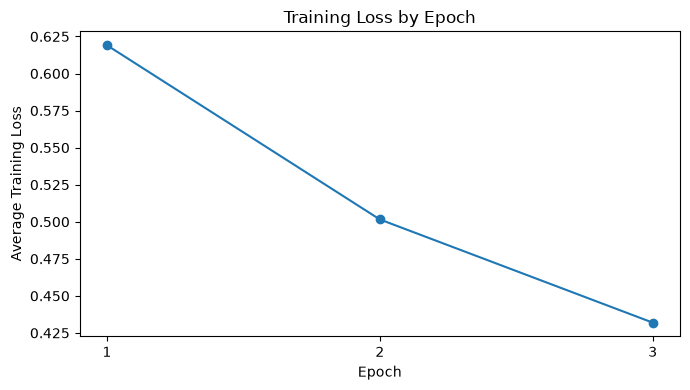

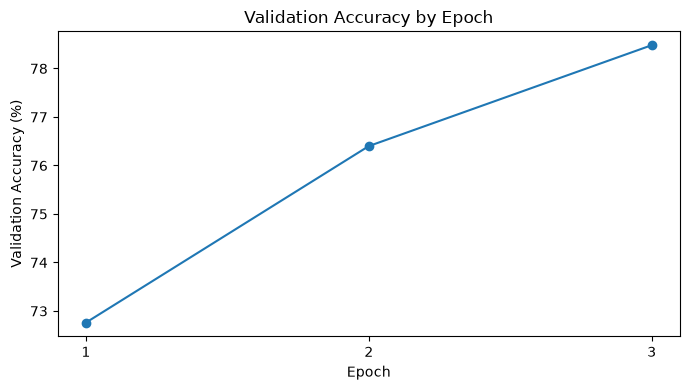

In [31]:
# Plot training loss and validation accuracy
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), history["train_loss"], marker="o")
plt.title("Training Loss by Epoch")
plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), history["val_accuracy"], marker="o")
plt.title("Validation Accuracy by Epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.xticks(range(1, EPOCHS + 1))
plt.tight_layout()
plt.show()

## 7. Test the Model

Run the following cell after training. The project target is **greater than 75% test accuracy**.

The exact value must be obtained by executing the notebook; it should not be hard-coded.

In [32]:
test_accuracy = calculate_accuracy(model, test_loader, device)
print(f"Test Accuracy: {test_accuracy:.2f}%")

if test_accuracy > 75:
    print("Project target achieved: test accuracy is greater than 75%.")
else:
    print("Project target not yet achieved. Consider additional training/optimization.")

Test Accuracy: 76.11%
Project target achieved: test accuracy is greater than 75%.


## 8. Conclusion

This project loads and explores the IMDB movie-review dataset, creates the required PyTorch dataset/data loaders, tokenizes reviews with `bert-base-uncased`, and trains a custom transformer model from scratch for binary sentiment classification.

### Key Takeaways

1. A GPT-style transformer can be adapted for classification by mean-pooling its sequence representations and adding a classification head.
2. Correct tokenization, padding, truncation, batching, and dataset preparation are essential for transformer training.
3. Validation accuracy provides a useful measure of how the model generalizes during training.
4. The final test accuracy should be reported from the executed `test_accuracy` cell rather than entered manually.

In [33]:
# Final result summary
print(f"Final test accuracy: {test_accuracy:.2f}%")
print("Training epochs:", EPOCHS)
print("Max sequence length:", MAX_LENGTH)
print("Batch size:", BATCH_SIZE)
print("Model configuration:", config)

Final test accuracy: 76.11%
Training epochs: 3
Max sequence length: 128
Batch size: 32
Model configuration: {'vocabulary_size': 30522, 'num_classes': 2, 'd_embed': 128, 'context_size': 128, 'layers_num': 4, 'heads_num': 4, 'head_size': 32, 'dropout_rate': 0.1, 'use_bias': True}


In [1]:
import torch
import transformers
import pandas
import sklearn

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Environment is working!")

PyTorch: 2.14.0+cpu
Transformers: 5.17.0
Environment is working!


In [6]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

Current folder:
C:\Users\HP\Downloads\SentimentScope_Project (1)\SentimentScope_Project

Files/folders here:
['.gitignore', '.idea', '.venv', 'aclImdb_v1', 'README.md', 'requirements.txt', 'SentimentScope_Completed.ipynb']


In [10]:
import os

print("Project folder:")
print(os.getcwd())

print("\nProject contents:")
print(os.listdir("."))

print("\nDataset contents:")
print(os.listdir("aclImdb"))

Project folder:
C:\Users\HP\Downloads\SentimentScope_Project (1)\SentimentScope_Project

Project contents:
['.gitignore', '.idea', '.venv', 'aclImdb', 'README.md', 'requirements.txt', 'SentimentScope_Completed.ipynb']

Dataset contents:
['aclImdb']
